#ISP Proposal: Minimal hardware requirements for continous sEMG estimation

By Santiago Martinez

*As part of the application for the ISP program*

---

## Overview

Bla bla bla

In [ ]:
# Already inside the local emg2pose repo — do not clone into notebooks/.
from pathlib import Path
import emg2pose

print("Using local install:", Path(emg2pose.__file__).resolve())
print("Data directory:", Path.home() / "emg2pose_dataset_mini")

Cloning into 'emg2pose'...
remote: Enumerating objects: 132, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 132 (delta 14), reused 11 (delta 11), pack-reused 81 (from 1)
Receiving objects: 100% (132/132), 1.36 MiB | 6.52 MiB/s, done.
Resolving deltas: 100% (18/18), done.
[Errno 2] No such file or directory: '/content/emg2pose'
~/Documents/Github/emg2pose/notebooks
ERROR: emg2pose/UmeTrack is not a valid editable requirement. It should either be a path to a local project or a VCS URL (beginning with bzr+http, bzr+https, bzr+ssh, bzr+sftp, bzr+ftp, bzr+lp, bzr+file, git+http, git+https, git+ssh, git+git, git+file, hg+file, hg+http, hg+https, hg+ssh, hg+static-http, svn+ssh, svn+http, svn+https, svn+svn, svn+file).
Obtaining file://~/Documents/Github/emg2pose/notebooks
ERROR: file://~/Documents/Github/emg2pose/notebooks does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.


In [ ]:
from pathlib import Path

DATA_DOWNLOAD_DIR = Path.home()
metadata_path = DATA_DOWNLOAD_DIR / "emg2pose_metadata.csv"

if metadata_path.exists():
    print(f"Already downloaded: {metadata_path}")
else:
    !cd {DATA_DOWNLOAD_DIR} && curl https://fb-ctrl-oss.s3.amazonaws.com/emg2pose/emg2pose_metadata.csv -o emg2pose_metadata.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 5541k  100 5541k    0     0  9089k      0 --:--:-- --:--:-- --:--:-- 9099k


In [ ]:
!curl "https://fb-ctrl-oss.s3.amazonaws.com/emg2pose/emg2pose_dataset_mini.tar" -o emg2pose_dataset_mini.tar #download the "mini" dataset
!tar -xvf emg2pose_dataset_mini.tar #extract

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  617M  100  617M    0     0  27.1M      0  0:00:22  0:00:22 --:--:-- 27.4M
emg2pose_dataset_mini/
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-13_right.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-3_left.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-1_right.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-15_left.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-5_left.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-4_right.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-13_left.hdf5
emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-8_left.hdf

In [ ]:
import h5py
import glob
import os
import matplotlib.pyplot as plt
dataset_dir = "emg2pose_dataset_mini"
h5_files = glob.glob(os.path.join(dataset_dir, "*.hdf5"))

def map_hdf5_structure(name, obj):
    if isinstance(obj, h5py.Group):
        print(f"Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"Dataset: {name} | Shape: {obj.shape} | Data Type: {obj.dtype}")

if not h5_files:
    print(f"No HDF5 files found in {dataset_dir}")
else:
    target_file = h5_files[0]
    print(f"Loading data from: {target_file}")

    with h5py.File(target_file, 'r') as f:
        time_data = f['emg2pose']['timeseries']['time'][:]
        joint_angles = f['emg2pose']['timeseries']['joint_angles'][:]
        emg_data = f['emg2pose']['timeseries']['emg'][:]

        print(f"Successfully loaded {len(time_data)} time steps.")
        print(f"EMG Data Shape: {emg_data.shape}")
        print(f"Joint Angles Shape: {joint_angles.shape}")
        f.visititems(map_hdf5_structure)



Loading data from: emg2pose_dataset_mini/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-13_right.hdf5
Successfully loaded 473792 time steps.
EMG Data Shape: (473792, 16)
Joint Angles Shape: (473792, 20)
Group: emg2pose
Dataset: emg2pose/timeseries | Shape: (473792,) | Data Type: [('time', '<f8'), ('joint_angles', '<f4', (20,)), ('emg', '<f4', (16,))]


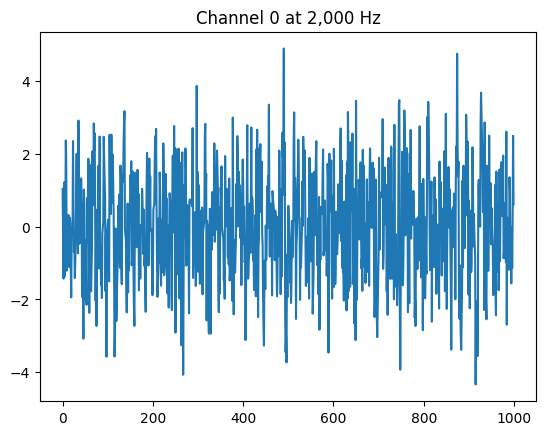

Validated Sample Frequency: 2000.144969003338 Hz


In [5]:
plt.plot(emg_data[:1000, 0])
plt.title("Channel 0 at 2,000 Hz")
plt.show()
# Calculate the time difference (delta t) between the second and first sample
delta_t = time_data[1] - time_data[0]

# Calculate frequency: f = 1 / dt
sample_frequency = 1 / delta_t

print(f"Validated Sample Frequency: {sample_frequency} Hz")

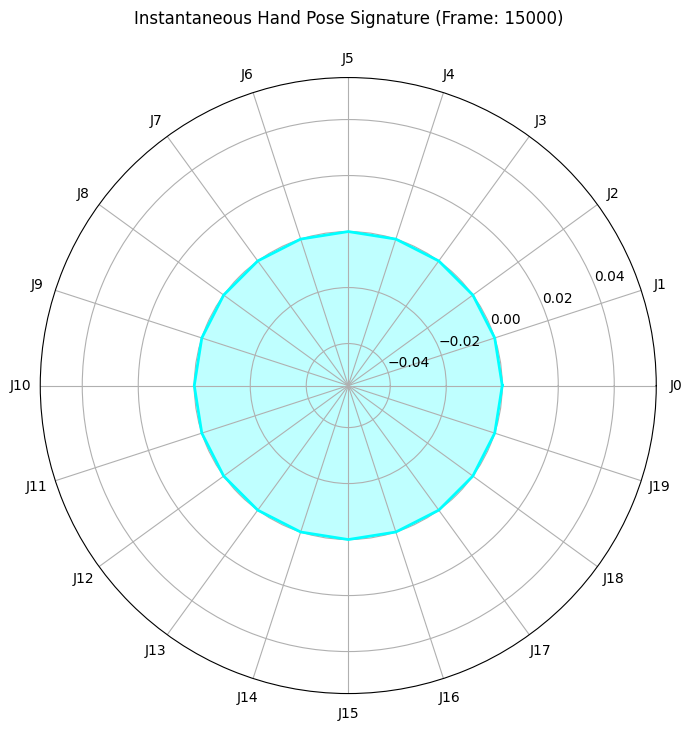

In [6]:
import matplotlib.pyplot as plt
import numpy as np

frame_idx = 15000
current_pose = joint_angles[frame_idx, :]

# Set up the radar chart axes
categories = [f'J{i}' for i in range(20)]
angles_rad = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()

# Close the polygon by appending the first value to the end
current_pose = np.concatenate((current_pose, [current_pose[0]]))
angles_rad += angles_rad[:1]

# Plotting
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.plot(angles_rad, current_pose, color='cyan', linewidth=2)
ax.fill(angles_rad, current_pose, color='cyan', alpha=0.25)

# Add labels
ax.set_xticks(angles_rad[:-1])
ax.set_xticklabels(categories)
ax.set_title(f"Instantaneous Hand Pose Signature (Frame: {frame_idx})", pad=20)

plt.show()

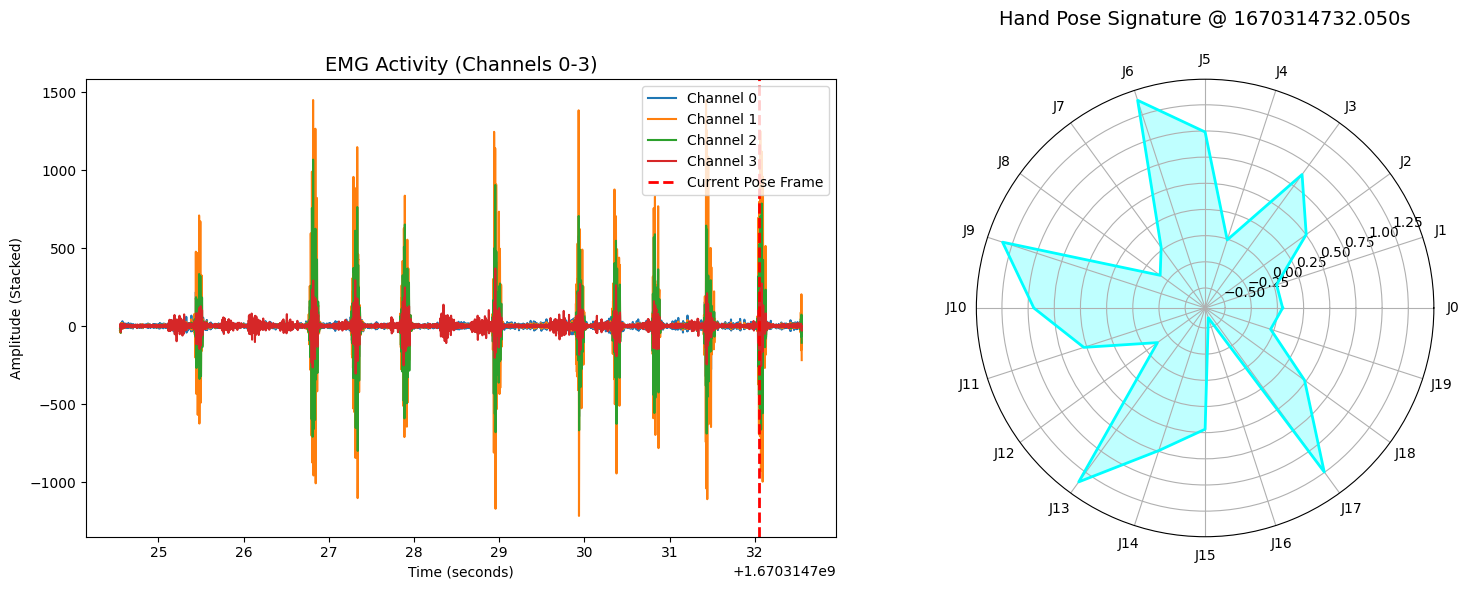

In [7]:
import matplotlib.pyplot as plt
import numpy as np

time_slice = time_data[4000:20000]
angles_slice = joint_angles[4000:20000, :]
emg_slice = emg_data[4000:20000, :]

frame_idx = 15000
time_at_frame = time_slice[frame_idx]
current_pose = angles_slice[frame_idx, :]

fig = plt.figure(figsize=(16, 6))

# ==========================================
# SUBPLOT 1: EMG Channels (Standard Plot)
# ==========================================
ax1 = fig.add_subplot(1, 2, 1)

# Plot the first 4 EMG channels, offsetting each by 0.5 so they don't overlap into a mess
for ch in range(4):
    ax1.plot(time_slice, emg_slice[:, ch] + (ch * 0.5), label=f'Channel {ch}')

# Draw a vertical line showing exactly where the radar chart is taking its snapshot
ax1.axvline(x=time_at_frame, color='red', linestyle='--', linewidth=2, label='Current Pose Frame')

ax1.set_title("EMG Activity (Channels 0-3)", fontsize=14)
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Amplitude (Stacked)")
ax1.legend(loc='upper right')

# ==========================================
# SUBPLOT 2: Joint Angles (Polar Plot)
# ==========================================
ax2 = fig.add_subplot(1, 2, 2, projection='polar')

categories = [f'J{i}' for i in range(20)]
angles_rad = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()

current_pose_closed = np.concatenate((current_pose, [current_pose[0]]))
angles_rad_closed = angles_rad + angles_rad[:1]

ax2.plot(angles_rad_closed, current_pose_closed, color='cyan', linewidth=2)
ax2.fill(angles_rad_closed, current_pose_closed, color='cyan', alpha=0.25)

ax2.set_xticks(angles_rad)
ax2.set_xticklabels(categories)
ax2.set_title(f"Hand Pose Signature @ {time_at_frame:.3f}s", pad=20, fontsize=14)

plt.tight_layout()
plt.show()

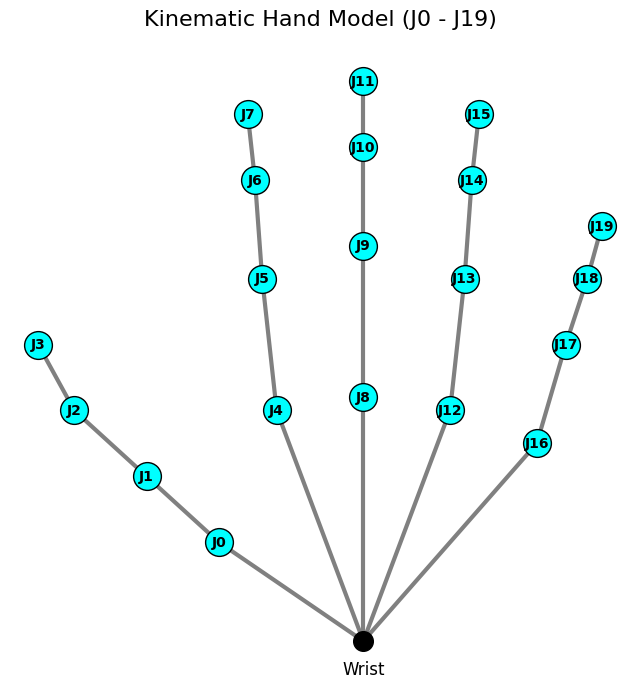

In [8]:
import matplotlib.pyplot as plt

# Approximate 2D coordinates for a standard hand skeleton (X, Y)
# Organized by finger: Thumb, Index, Middle, Ring, Pinky
# Each digit has 4 nodes (joints) moving from base to tip
hand_nodes = {
    # Thumb (J0 - J3)
    'J0': (-2.0, 1.5), 'J1': (-3.0, 2.5), 'J2': (-4.0, 3.5), 'J3': (-4.5, 4.5),
    # Index (J4 - J7)
    'J4': (-1.2, 3.5), 'J5': (-1.4, 5.5), 'J6': (-1.5, 7.0), 'J7': (-1.6, 8.0),
    # Middle (J8 - J11)
    'J8': (0.0, 3.7), 'J9': (0.0, 6.0), 'J10': (0.0, 7.5), 'J11': (0.0, 8.5),
    # Ring (J12 - J15)
    'J12': (1.2, 3.5), 'J13': (1.4, 5.5), 'J14': (1.5, 7.0), 'J15': (1.6, 8.0),
    # Pinky (J16 - J19)
    'J16': (2.4, 3.0), 'J17': (2.8, 4.5), 'J18': (3.1, 5.5), 'J19': (3.3, 6.3)
}

# Define the connections (bones) to draw lines between joints
bones = [
    # Connect base of fingers to a theoretical "Wrist" at (0,0)
    ((0,0), hand_nodes['J0']), ((0,0), hand_nodes['J4']),
    ((0,0), hand_nodes['J8']), ((0,0), hand_nodes['J12']), ((0,0), hand_nodes['J16']),
    # Thumb bones
    (hand_nodes['J0'], hand_nodes['J1']), (hand_nodes['J1'], hand_nodes['J2']), (hand_nodes['J2'], hand_nodes['J3']),
    # Index bones
    (hand_nodes['J4'], hand_nodes['J5']), (hand_nodes['J5'], hand_nodes['J6']), (hand_nodes['J6'], hand_nodes['J7']),
    # Middle bones
    (hand_nodes['J8'], hand_nodes['J9']), (hand_nodes['J9'], hand_nodes['J10']), (hand_nodes['J10'], hand_nodes['J11']),
    # Ring bones
    (hand_nodes['J12'], hand_nodes['J13']), (hand_nodes['J13'], hand_nodes['J14']), (hand_nodes['J14'], hand_nodes['J15']),
    # Pinky bones
    (hand_nodes['J16'], hand_nodes['J17']), (hand_nodes['J17'], hand_nodes['J18']), (hand_nodes['J18'], hand_nodes['J19'])
]

fig, ax = plt.subplots(figsize=(8, 8))

# Draw the bones
for bone in bones:
    start, end = bone
    ax.plot([start[0], end[0]], [start[1], end[1]], 'gray', linewidth=3, zorder=1)

# Draw and label the joints
for joint_name, coords in hand_nodes.items():
    ax.scatter(coords[0], coords[1], s=400, color='cyan', edgecolor='black', zorder=2)
    ax.text(coords[0], coords[1], joint_name, fontsize=10, ha='center', va='center', fontweight='bold', zorder=3)

# Draw the wrist reference point
ax.scatter(0, 0, s=200, color='black', zorder=2)
ax.text(0, -0.5, 'Wrist', fontsize=12, ha='center')

ax.set_title("Kinematic Hand Model (J0 - J19)", fontsize=16, pad=20)
ax.axis('off')
plt.show()

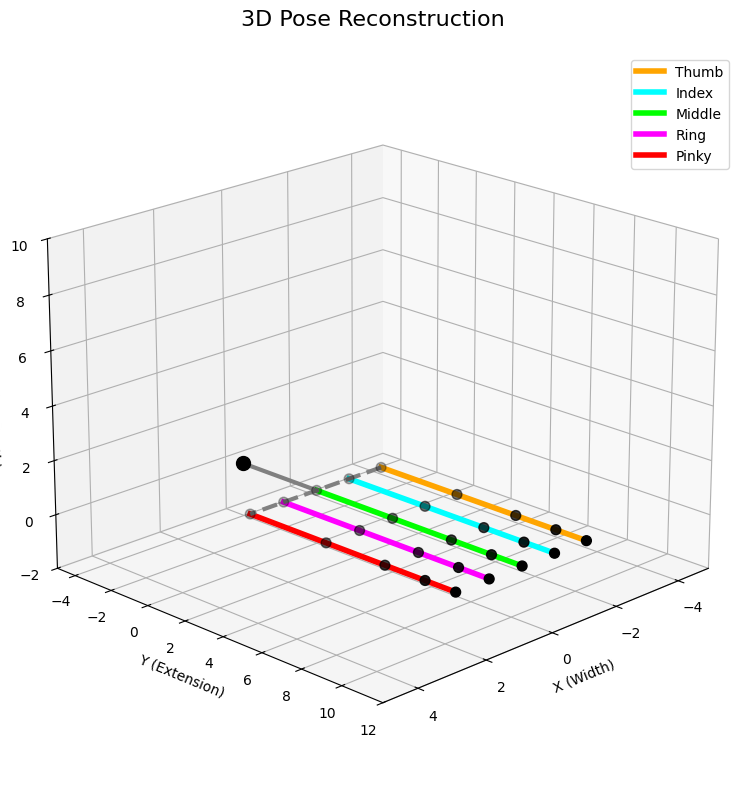

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_3d_hand(angles_20d):
    """
    A simplified Forward Kinematics (FK) solver.
    Converts 20 joint angles into 3D Cartesian coordinates (X, Y, Z).
    """
    # Define approximate base positions for the 5 digits (spread along the X-axis)
    # Order: Thumb, Index, Middle, Ring, Pinky
    bases = [(-2.0, 0, 0), (-1.0, 0, 0), (0.0, 0, 0), (1.0, 0, 0), (2.0, 0, 0)]

    # Approximate bone lengths in cm (from base to tip)
    bone_lengths = [4.0, 3.0, 2.0, 1.5]

    fingers_xyz = []

    for f_idx in range(5):
        # Extract the 4 specific angles for this digit
        f_angles = angles_20d[f_idx * 4 : (f_idx + 1) * 4]

        # Initialize lists with the base knuckle position
        x, y, z = [bases[f_idx][0]], [bases[f_idx][1]], [bases[f_idx][2]]

        current_pos = np.array(bases[f_idx])
        cumulative_angle = 0

        for b_idx in range(4):
            # Accumulate the flexion angle as we move down the finger
            cumulative_angle += f_angles[b_idx]

            # Calculate the next joint's position using simple trigonometry
            # Bending primarily in the Y-Z plane for this visualization
            dy = bone_lengths[b_idx] * np.cos(cumulative_angle)
            dz = bone_lengths[b_idx] * np.sin(cumulative_angle)

            next_pos = current_pos + np.array([0, dy, dz])

            x.append(next_pos[0])
            y.append(next_pos[1])
            z.append(next_pos[2])

            current_pos = next_pos

        fingers_xyz.append((x, y, z))

    return fingers_xyz

# ==========================================
# Generate and Plot the 3D Hand
# ==========================================
# 1. Grab your specific frame (using dummy data here for illustration)
# Replace `mock_angles` with your actual `angles_slice[frame_idx, :]`
np.random.seed(42)
# Creating a mock "pointing" gesture for demonstration
mock_angles = np.zeros(20)
mock_angles[8:20] = 1.0  # Curl middle, ring, pinky fingers tightly

# 2. Calculate the 3D points
fingers_3d = calculate_3d_hand(joint_angles[15000,:])

# 3. Plotting
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

colors = ['orange', 'cyan', 'lime', 'magenta', 'red']
labels = ['Thumb', 'Index', 'Middle', 'Ring', 'Pinky']

# Draw each finger
for i, (x, y, z) in enumerate(fingers_3d):
    # Draw the bones (lines)
    ax.plot(x, y, z, color=colors[i], linewidth=4, label=labels[i])
    # Draw the joints (scatter points)
    ax.scatter(x, y, z, color='black', s=50, zorder=5)

# Draw the palm (connecting the bases)
base_x = [f[0][0] for f in fingers_3d]
base_y = [f[1][0] for f in fingers_3d]
base_z = [f[2][0] for f in fingers_3d]
ax.plot(base_x, base_y, base_z, color='gray', linewidth=3, linestyle='--')
ax.scatter(0, -4, 0, color='black', s=100) # Fake wrist point
ax.plot([0, base_x[2]], [-4, base_y[2]], [0, base_z[2]], color='gray', linewidth=3)

# Formatting the 3D space
ax.set_title('3D Pose Reconstruction', fontsize=16, pad=20)
ax.set_xlabel('X (Width)')
ax.set_ylabel('Y (Extension)')
ax.set_zlabel('Z (Flexion Depth)')

# Set consistent limits so the hand doesn't warp when moving
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 12)
ax.set_zlim(-2, 10)
ax.view_init(elev=20, azim=45) # Set a nice isometric viewing angle

plt.legend()
plt.tight_layout()
plt.show()